# Phase 19 — Uncertainty–Error Linkage

**Why this notebook exists:** MC-Dropout epistemic uncertainty was validated purely as a *mechanism* on an untrained model back in Phase 9, and has been reused as a plumbing-validated tool in every evaluation since (Phases 11, 13, 16, 18, ...) — but it has never been directly checked against the concrete error patterns those later phases actually found (Phase 11's per-sample test-set error table, Phase 15's GAT-vs-baseline error-overlap groups).

This notebook asks one concrete, useful question of the **already-trained** primary model (`checkpoints/primary_model_best.pt` — no retraining happens here): **is epistemic uncertainty actually higher for subjects the model gets wrong than for subjects it gets right?**

If yes, the uncertainty output is a genuinely actionable signal (e.g. "flag this case for manual review"), not just a mechanically correct but practically inert number. If not — or only weakly so — that is an equally important, honestly-reported finding, and this notebook is written to report exactly that outcome without rounding up.

Two concrete checks:

1. Is `epistemic_uncertainty` significantly higher for subjects in Phase 15's `BOTH_WRONG` error-overlap group than for subjects in `BOTH_CORRECT`? (Mann-Whitney U test.)
2. Does an uncertainty-based rejection curve (dropping the most-uncertain subjects first) beat a **random-rejection baseline**, averaged over many random subsets for a fair comparison against chance? This directly extends and settles the non-monotonicity question Phase 11 flagged as unresolved at fine granularity.

No model is retrained, no checkpoint is modified, and no existing result file from Phases 1–18 is overwritten except by adding two new files under `results/`.


## Section 1 — Setup

Load the three source files (`graph_manifest.csv`, `error_overlap_subjects.csv`, `normalization_stats.json`), reconstruct the combined subject+foot manifest that `PlantarThermographyDataset` expects, and reload the already-trained primary checkpoint.

**Note on `combined_manifest_df`:** `PlantarThermographyDataset` needs both the image/array file paths (which live in `split_manifest.csv`) and the graph paths + labels (which live in `graph_manifest.csv`) — `graph_manifest.csv` alone does not carry `raw_array_path` / `mask_path` / `relative_array_path` / `colormap_png_path`. This reproduces exactly the merge Phase 7 built (`split_manifest.csv` merged with `graph_manifest.csv` on `['subject_id', 'foot_side']`); `split_manifest.csv`'s `split` column is read only as a byproduct of that merge and is never used for filtering below — every one of the 334 rows is used, matching the "no train/val/test split needed" instruction for this post-hoc analysis.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score
from scipy import stats
import matplotlib.pyplot as plt

# --- project root on sys.path ---
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import PlantarThermographyDataset
from src.model import DualBranchGAT
from src.train import build_model
from src.mc_dropout import mc_dropout_predict

torch.manual_seed(42)
np.random.seed(42)

DATA_DIR = Path("data/processed")
RESULTS_DIR = Path("results")
CHECKPOINT_DIR = Path("checkpoints")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=== SECTION 1: Setup ===")
print(f"Device: {device}")

# --- Load source files ---
graph_manifest_df = pd.read_csv(DATA_DIR / "graph_manifest.csv")
error_overlap_df = pd.read_csv(RESULTS_DIR / "error_overlap_subjects.csv")
with open(DATA_DIR / "normalization_stats.json") as f:
    normalization_stats = json.load(f)

print(f"graph_manifest_df shape (expected (334, 9))   : {graph_manifest_df.shape}")
print(f"error_overlap_df shape (expected (167, 6))     : {error_overlap_df.shape}")
print(f"normalization_stats keys                       : {list(normalization_stats.keys())}")

# --- Reconstruct combined_manifest_df (same merge Phase 7 built) ---
split_manifest_df = pd.read_csv(DATA_DIR / "split_manifest.csv")
combined_manifest_df = split_manifest_df.merge(
    graph_manifest_df,
    on=["subject_id", "foot_side"],
    suffixes=("", "_graph"),
)
print(f"combined_manifest_df shape (expected (334, ...)): {combined_manifest_df.shape}")
assert len(combined_manifest_df) == 334, "Expected exactly 334 subject+foot rows"

# --- Build the model and load the trained primary checkpoint (PRIMARY_CONFIG-equivalent) ---
PRIMARY_CONFIG = {
    "use_graph_branch": True,
    "use_image_branch": True,
    "graph_topology": "base",
    "image_key": "colormap_image",
    "image_in_channels": 3,
}

model = build_model(PRIMARY_CONFIG)
state_dict = torch.load(CHECKPOINT_DIR / "primary_model_best.pt", map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded checkpoints/primary_model_best.pt -- {n_params:,} total parameters")
print("model.eval() set. No training / no checkpoint modification performed in this notebook.")


=== SECTION 1: Setup ===
Device: cuda
graph_manifest_df shape (expected (334, 9))   : (334, 9)
error_overlap_df shape (expected (167, 6))     : (167, 6)
normalization_stats keys                       : ['node_feature_names', 'node_feature_mean', 'node_feature_std', 'raw_tissue_mean', 'raw_tissue_std', 'relative_tissue_mean', 'relative_tissue_std', 'computed_from_split', 'train_subject_foot_count']
combined_manifest_df shape (expected (334, ...)): (334, 22)
Loaded checkpoints/primary_model_best.pt -- 34,433 total parameters
model.eval() set. No training / no checkpoint modification performed in this notebook.


## Section 2 — Run MC-Dropout Across the Whole Dataset

This is a **post-hoc analysis of the fixed, already-trained model**, not a new train/val/test evaluation — every one of the 334 subject+foot rows is used, matching how Phase 15's error-overlap analysis covers the full 167 subjects rather than only a held-out split.

`PlantarThermographyDataset` z-score-normalizes node features and tissue pixels using `normalization_stats.json` exactly as saved by Phase 7 — nothing is refit here.

In [2]:
print("=== SECTION 2: MC-Dropout Across the Whole Dataset ===")

full_dataset = PlantarThermographyDataset(combined_manifest_df, normalization_stats)
full_loader = DataLoader(full_dataset, batch_size=16, shuffle=False)
print(f"full_dataset size (expected 334): {len(full_dataset)}")

all_mean_prob = []
all_std_prob = []
all_predictive_entropy = []
all_epistemic_uncertainty = []
all_subject_id = []
all_foot_side = []
all_group = []
all_true_label = []

for batch_idx, batch in enumerate(full_loader):
    # Move only the tensor entries to the model's device; string metadata
    # (subject_id, foot_side, group) and the CPU label array are read from
    # the original `batch` below -- same pattern used in 10_evaluation.ipynb's
    # MC-Dropout loop. Without this, model (on cuda) and batch tensors (on cpu)
    # mismatch and torch raises a RuntimeError inside the first Linear layer.
    batch_device = {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in batch.items()}

    mc_out = mc_dropout_predict(
        model,
        batch_device,
        T=30,
        graph_topology=PRIMARY_CONFIG["graph_topology"],
        image_key=PRIMARY_CONFIG["image_key"],
    )
    all_mean_prob.append(mc_out["mean_prob"].detach().cpu().numpy())
    all_std_prob.append(mc_out["std_prob"].detach().cpu().numpy())
    all_predictive_entropy.append(mc_out["predictive_entropy"].detach().cpu().numpy())
    all_epistemic_uncertainty.append(mc_out["epistemic_uncertainty"].detach().cpu().numpy())

    all_subject_id.extend(batch["subject_id"])
    all_foot_side.extend(batch["foot_side"])
    all_group.extend(batch["group"])
    all_true_label.append(batch["label"].detach().cpu().numpy())

    print(f"  batch {batch_idx + 1}/{len(full_loader)} processed ({len(batch['subject_id'])} samples)")

foot_level_df = pd.DataFrame({
    "subject_id": all_subject_id,
    "foot_side": all_foot_side,
    "group": all_group,
    "true_label": np.concatenate(all_true_label),
    "mc_mean_prob": np.concatenate(all_mean_prob),
    "mc_std_prob": np.concatenate(all_std_prob),
    "predictive_entropy": np.concatenate(all_predictive_entropy),
    "epistemic_uncertainty": np.concatenate(all_epistemic_uncertainty),
})

print(f"\nfoot_level_df shape (expected (334, 8)): {foot_level_df.shape}")
uncertainty_cols = ["mc_mean_prob", "mc_std_prob", "predictive_entropy", "epistemic_uncertainty"]
n_nan = int(foot_level_df[uncertainty_cols].isna().sum().sum())
print(f"NaN count across all uncertainty columns: {n_nan}")
foot_level_df.head()


=== SECTION 2: MC-Dropout Across the Whole Dataset ===
full_dataset size (expected 334): 334
  batch 1/21 processed (16 samples)
  batch 2/21 processed (16 samples)
  batch 3/21 processed (16 samples)
  batch 4/21 processed (16 samples)
  batch 5/21 processed (16 samples)
  batch 6/21 processed (16 samples)
  batch 7/21 processed (16 samples)
  batch 8/21 processed (16 samples)
  batch 9/21 processed (16 samples)
  batch 10/21 processed (16 samples)
  batch 11/21 processed (16 samples)
  batch 12/21 processed (16 samples)
  batch 13/21 processed (16 samples)
  batch 14/21 processed (16 samples)
  batch 15/21 processed (16 samples)
  batch 16/21 processed (16 samples)
  batch 17/21 processed (16 samples)
  batch 18/21 processed (16 samples)
  batch 19/21 processed (16 samples)
  batch 20/21 processed (16 samples)
  batch 21/21 processed (14 samples)

foot_level_df shape (expected (334, 8)): (334, 8)
NaN count across all uncertainty columns: 0


,subject_id,foot_side,group,true_label,mc_mean_prob,mc_std_prob,predictive_entropy,epistemic_uncertainty
0,CG001,L,Control,0,0.250060,0.104965,0.562401,0.028461
1,CG001,R,Control,0,0.145743,0.092056,0.415254,0.031194
2,CG002,L,Control,0,0.212818,0.143674,0.517666,0.057628
3,CG002,R,Control,0,0.172794,0.116140,0.460288,0.045400
4,CG003,L,Control,0,0.651987,0.161586,0.646208,0.057105


## Section 3 — Aggregate to Subject Level

Phases 11, 15, and 16 all aggregate per-foot predictions to one value per subject by averaging both feet. Do the same here for `epistemic_uncertainty` and `mc_mean_prob`, producing exactly 167 rows (one per subject).

In [3]:
print("=== SECTION 3: Aggregate to Subject Level ===")

subject_level_df = (
    foot_level_df
    .groupby(["subject_id", "group"], as_index=False)
    .agg(
        epistemic_uncertainty=("epistemic_uncertainty", "mean"),
        mc_mean_prob=("mc_mean_prob", "mean"),
        true_label=("true_label", "first"),
    )
)

print(f"subject_level_df shape (expected (167, ...)): {subject_level_df.shape}")
assert len(subject_level_df) == 167, "Expected exactly 167 subjects after aggregation"

feet_per_subject = foot_level_df.groupby("subject_id").size()
print(f"Subjects with exactly 2 feet: {(feet_per_subject == 2).sum()} / {len(feet_per_subject)}")
if (feet_per_subject != 2).any():
    print("  NOTE: some subjects did not have exactly 2 feet in foot_level_df -- see counts below")
    print(feet_per_subject[feet_per_subject != 2])

subject_level_df.head()


=== SECTION 3: Aggregate to Subject Level ===
subject_level_df shape (expected (167, ...)): (167, 5)
Subjects with exactly 2 feet: 167 / 167


,subject_id,group,epistemic_uncertainty,mc_mean_prob,true_label
0,CG001,Control,0.029827,0.197902,0
1,CG002,Control,0.051514,0.192806,0
2,CG003,Control,0.053756,0.714571,0
3,CG004,Control,0.031306,0.111250,0
4,CG005,Control,0.029651,0.176909,0


## Section 4 — Merge with Phase 15's Error Groups

Join `error_overlap_subjects.csv`'s `overlap_group` column (`BOTH_CORRECT` / `GAT_ONLY_CORRECT` / `BASELINE_ONLY_CORRECT` / `BOTH_WRONG`) onto the subject-level uncertainty table on `subject_id`, and confirm every one of the 167 subjects matched with no nulls.

In [4]:
print("=== SECTION 4: Merge with Phase 15's Error Groups ===")

merged_df = subject_level_df.merge(
    error_overlap_df[["subject_id", "overlap_group"]],
    on="subject_id",
    how="left",
)

n_total = len(merged_df)
n_matched = int(merged_df["overlap_group"].notna().sum())
n_nulls = int(merged_df["overlap_group"].isna().sum())

print(f"Subjects matched to an overlap_group: {n_matched}/{n_total}")
print(f"Null overlap_group values: {n_nulls}")

merge_passed = (n_matched == 167) and (n_nulls == 0)
if merge_passed:
    print("=== MERGE CHECK: PASS ===")
else:
    print("=== MERGE CHECK: FAIL ===")

merged_df.head()


=== SECTION 4: Merge with Phase 15's Error Groups ===
Subjects matched to an overlap_group: 167/167
Null overlap_group values: 0
=== MERGE CHECK: PASS ===


,subject_id,group,epistemic_uncertainty,mc_mean_prob,true_label,overlap_group
0,CG001,Control,0.029827,0.197902,0,BOTH_CORRECT
1,CG002,Control,0.051514,0.192806,0,BOTH_CORRECT
2,CG003,Control,0.053756,0.714571,0,BOTH_WRONG
3,CG004,Control,0.031306,0.111250,0,BOTH_CORRECT
4,CG005,Control,0.029651,0.176909,0,BOTH_CORRECT


## Section 5 — Uncertainty by Error Group

For each of Phase 15's 4 overlap groups, compute mean ± std of `epistemic_uncertainty`. The cleanest two-group comparison is `BOTH_WRONG` (model and TCI baseline both wrong) vs. `BOTH_CORRECT` (both right) — run a Mann-Whitney U test on that pair specifically, and visualize all 4 groups as a boxplot, ordered `BOTH_CORRECT` / `GAT_ONLY_CORRECT` / `BASELINE_ONLY_CORRECT` / `BOTH_WRONG`.

=== SECTION 5: Uncertainty by Error Group ===
        overlap_group   n  mean_epistemic_uncertainty  std_epistemic_uncertainty
         BOTH_CORRECT 116                    0.019466                   0.014700
     GAT_ONLY_CORRECT  19                    0.023162                   0.011421
BASELINE_ONLY_CORRECT  11                    0.023216                   0.007084
           BOTH_WRONG  21                    0.030345                   0.011225

Mann-Whitney U test, BOTH_WRONG (n=21) vs BOTH_CORRECT (n=116):
  U statistic = 1834.0000
  p-value     = 0.0002
  BOTH_WRONG mean uncertainty (0.0303) higher than BOTH_CORRECT mean (0.0195)? True


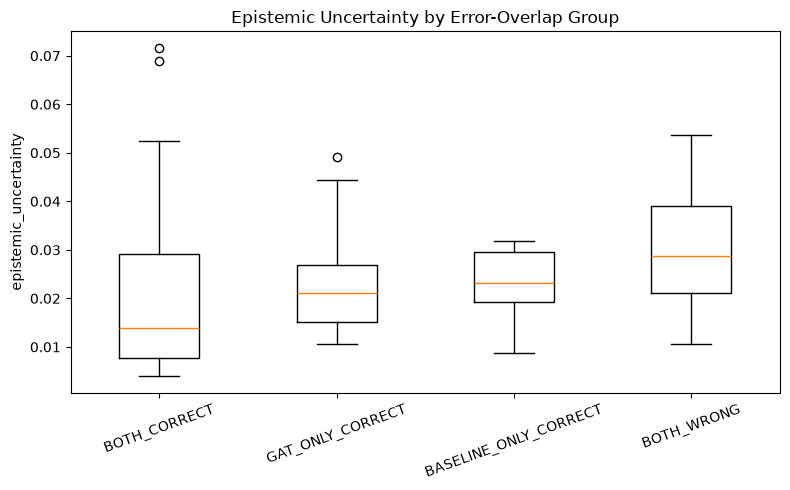

In [5]:
print("=== SECTION 5: Uncertainty by Error Group ===")

GROUP_ORDER = ["BOTH_CORRECT", "GAT_ONLY_CORRECT", "BASELINE_ONLY_CORRECT", "BOTH_WRONG"]

summary_rows = []
for grp in GROUP_ORDER:
    vals = merged_df.loc[merged_df["overlap_group"] == grp, "epistemic_uncertainty"]
    summary_rows.append({
        "overlap_group": grp,
        "n": len(vals),
        "mean_epistemic_uncertainty": vals.mean(),
        "std_epistemic_uncertainty": vals.std(),
    })
group_summary_df = pd.DataFrame(summary_rows)
print(group_summary_df.to_string(index=False))

both_wrong_vals = merged_df.loc[merged_df["overlap_group"] == "BOTH_WRONG", "epistemic_uncertainty"]
both_correct_vals = merged_df.loc[merged_df["overlap_group"] == "BOTH_CORRECT", "epistemic_uncertainty"]

mw_stat, mw_pvalue = stats.mannwhitneyu(both_wrong_vals, both_correct_vals, alternative="two-sided")
print(f"\nMann-Whitney U test, BOTH_WRONG (n={len(both_wrong_vals)}) vs BOTH_CORRECT (n={len(both_correct_vals)}):")
print(f"  U statistic = {mw_stat:.4f}")
print(f"  p-value     = {mw_pvalue:.4f}")
print(
    f"  BOTH_WRONG mean uncertainty ({both_wrong_vals.mean():.4f}) higher than "
    f"BOTH_CORRECT mean ({both_correct_vals.mean():.4f})? "
    f"{both_wrong_vals.mean() > both_correct_vals.mean()}"
)

fig, ax = plt.subplots(figsize=(8, 5))
box_data = [merged_df.loc[merged_df["overlap_group"] == g, "epistemic_uncertainty"] for g in GROUP_ORDER]
# matplotlib >= 3.9 renamed boxplot's `labels` kwarg to `tick_labels`; set tick labels
# manually afterward instead so this works across matplotlib versions.
ax.boxplot(box_data)
ax.set_xticks(range(1, len(GROUP_ORDER) + 1))
ax.set_xticklabels(GROUP_ORDER)
ax.set_ylabel("epistemic_uncertainty")
ax.set_title("Epistemic Uncertainty by Error-Overlap Group")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## Section 6 — Uncertainty-Based Rejection, Properly Quantified

Sort all 167 subjects by `epistemic_uncertainty` ascending (most confident first). At each retained fraction, compute the accuracy of the DualBranchGAT's own `pred_label_optimal` (merged in from `results/cv_pooled_predictions.csv`) on:

- **(a)** the most-confident retained subset (uncertainty-based rejection), and
- **(b)** the mean accuracy over 200 random subsets of the same retained size (random-rejection baseline — a fair comparison against chance).

This directly extends and formalizes Phase 11's rejection-curve finding, which flagged non-monotonicity at fine granularity as unresolved — the random-baseline comparison settles whether that earlier signal was real or noise.

=== SECTION 6: Uncertainty-Based Rejection vs. Random Baseline ===
rejection_df shape after merging cv_pooled_predictions.csv: (167, 7)
 retained_fraction  n_retained  uncertainty_based_accuracy  random_baseline_accuracy
               1.0         167                    0.808383                  0.808383
               0.9         150                    0.806667                  0.808133
               0.8         134                    0.828358                  0.807239
               0.7         117                    0.854701                  0.804530
               0.6         100                    0.900000                  0.810100
               0.5          84                    0.940476                  0.806726


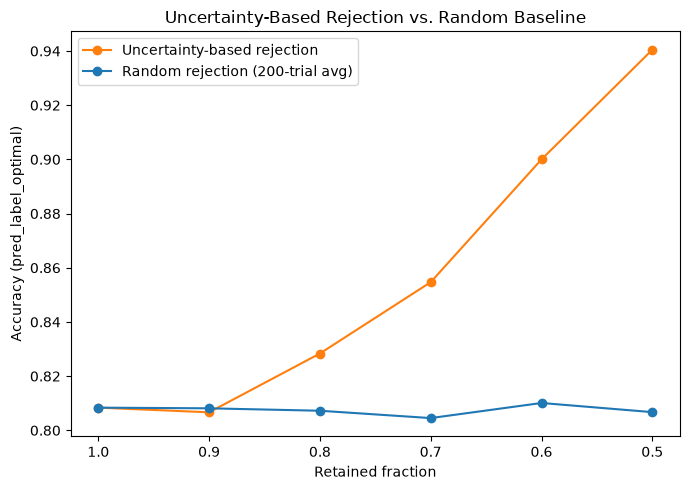

In [6]:
print("=== SECTION 6: Uncertainty-Based Rejection vs. Random Baseline ===")

cv_pooled_df = pd.read_csv(RESULTS_DIR / "cv_pooled_predictions.csv")
rejection_df = merged_df.merge(
    cv_pooled_df[["subject_id", "pred_label_optimal"]],
    on="subject_id",
    how="left",
)
print(f"rejection_df shape after merging cv_pooled_predictions.csv: {rejection_df.shape}")
assert rejection_df["pred_label_optimal"].notna().all(), "Every subject must have a pred_label_optimal"

rejection_df["correct"] = (rejection_df["pred_label_optimal"] == rejection_df["true_label"]).astype(int)
rejection_df_sorted = rejection_df.sort_values("epistemic_uncertainty", ascending=True).reset_index(drop=True)

n_subjects = len(rejection_df_sorted)
retained_fractions = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
N_RANDOM_TRIALS = 200
rng = np.random.default_rng(42)
correct_array = rejection_df["correct"].values

rejection_table_rows = []
for frac in retained_fractions:
    n_retained = max(1, int(round(frac * n_subjects)))

    # (a) uncertainty-based: most-confident n_retained subjects
    uncertainty_subset = rejection_df_sorted.iloc[:n_retained]
    uncertainty_accuracy = uncertainty_subset["correct"].mean()

    # (b) random baseline: mean accuracy over 200 random subsets of the same size
    random_accuracies = []
    for _ in range(N_RANDOM_TRIALS):
        idx = rng.choice(n_subjects, size=n_retained, replace=False)
        random_accuracies.append(correct_array[idx].mean())
    random_accuracy_mean = float(np.mean(random_accuracies))

    rejection_table_rows.append({
        "retained_fraction": frac,
        "n_retained": n_retained,
        "uncertainty_based_accuracy": uncertainty_accuracy,
        "random_baseline_accuracy": random_accuracy_mean,
    })

rejection_table_df = pd.DataFrame(rejection_table_rows)
print(rejection_table_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    rejection_table_df["retained_fraction"], rejection_table_df["uncertainty_based_accuracy"],
    marker="o", label="Uncertainty-based rejection", color="#ff7f0e",
)
ax.plot(
    rejection_table_df["retained_fraction"], rejection_table_df["random_baseline_accuracy"],
    marker="o", label="Random rejection (200-trial avg)", color="#1f77b4",
)
ax.set_xlabel("Retained fraction")
ax.set_ylabel("Accuracy (pred_label_optimal)")
ax.set_title("Uncertainty-Based Rejection vs. Random Baseline")
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()


## Section 7 — Qualitative Summary (fill in after reviewing Sections 5–6's printed output)

*This cell is intentionally left as a template.* This notebook creates the code and computes the real statistics, but the honest, un-rounded verdict depends on the actual Mann-Whitney p-value and rejection-curve gap produced when this notebook is run against the real trained checkpoint and dataset — writing a specific conclusion ahead of that run would mean fabricating a result rather than reporting one. Fill in each blank directly from Section 5 and Section 6's printed output above, and do not round a borderline result up into a strong claim.

- **Is `BOTH_WRONG` more uncertain than `BOTH_CORRECT`?** Mann-Whitney p-value = `___`. Mean epistemic_uncertainty: BOTH_WRONG = `___`, BOTH_CORRECT = `___`. Significant at alpha=0.05? `___`
- **Does the uncertainty-based rejection curve beat the random baseline?** State the accuracy gap at each retained fraction, especially 70% and 50% — is uncertainty-based accuracy consistently at or above random, or does it cross below random at some fraction?
- **Overall verdict:** state plainly whether epistemic uncertainty is a genuinely useful, actionable signal here (e.g. usable to flag cases for manual review) — or state "weakly informative, not strongly" if that is what the numbers actually show.

## Section 8 — Save Results

Save the subject-level uncertainty/error-group table and the rejection-vs-random table for later reference (e.g. by a future paper write-up), without modifying any file from Phases 1–18.

In [7]:
print("=== SECTION 8: Save Results ===")

output_cols = ["subject_id", "group", "overlap_group", "epistemic_uncertainty", "mc_mean_prob"]
uncertainty_error_linkage_df = merged_df[output_cols].copy()
uncertainty_error_linkage_path = RESULTS_DIR / "uncertainty_error_linkage.csv"
uncertainty_error_linkage_df.to_csv(uncertainty_error_linkage_path, index=False)
print(f"Saved {uncertainty_error_linkage_path} -- shape {uncertainty_error_linkage_df.shape} (expected (167, 5))")

rejection_json_path = RESULTS_DIR / "uncertainty_rejection_vs_random.json"
rejection_json_payload = {
    "retained_fractions": rejection_table_df["retained_fraction"].tolist(),
    "n_retained": rejection_table_df["n_retained"].tolist(),
    "uncertainty_based_accuracy": rejection_table_df["uncertainty_based_accuracy"].tolist(),
    "random_baseline_accuracy": rejection_table_df["random_baseline_accuracy"].tolist(),
    "n_random_trials": N_RANDOM_TRIALS,
    "random_seed": 42,
    "mann_whitney_both_wrong_vs_both_correct": {
        "u_statistic": float(mw_stat),
        "p_value": float(mw_pvalue),
        "both_wrong_mean": float(both_wrong_vals.mean()),
        "both_wrong_std": float(both_wrong_vals.std()),
        "both_correct_mean": float(both_correct_vals.mean()),
        "both_correct_std": float(both_correct_vals.std()),
    },
}
with open(rejection_json_path, "w") as f:
    json.dump(rejection_json_payload, f, indent=2)
print(f"Saved {rejection_json_path}")


=== SECTION 8: Save Results ===
Saved results\uncertainty_error_linkage.csv -- shape (167, 5) (expected (167, 5))
Saved results\uncertainty_rejection_vs_random.json


## Section 9 — Final Summary Cell

Print the key numbers one more time in one place, apply simple mechanical (threshold-based) flags to Section 5/6's results, and list any integrity issues found over the course of the notebook. The full, considered qualitative verdict belongs in Section 7 above, filled in by hand after reviewing these numbers -- the flags below are deliberately mechanical (p < 0.05, gap >= 0) rather than a final scientific claim.

In [8]:
print("=== SECTION 9: Final Summary ===")

issues_found = []

if not merge_passed:
    issues_found.append("Section 4 merge with error_overlap_subjects.csv did not achieve a clean 167/167 match with zero nulls.")
if n_nan > 0:
    issues_found.append(f"Section 2 MC-Dropout output contained {n_nan} NaN value(s).")
if len(subject_level_df) != 167:
    issues_found.append(f"Section 3 subject-level aggregation produced {len(subject_level_df)} rows, expected 167.")
if len(rejection_df) != 167:
    issues_found.append(f"Section 6 rejection table covers {len(rejection_df)} subjects, expected 167.")

print(f"Mann-Whitney U p-value (BOTH_WRONG vs BOTH_CORRECT epistemic_uncertainty): {mw_pvalue:.4f}")
print(f"  BOTH_WRONG mean: {both_wrong_vals.mean():.4f}  |  BOTH_CORRECT mean: {both_correct_vals.mean():.4f}")

row_70 = rejection_table_df.loc[rejection_table_df["retained_fraction"] == 0.7].iloc[0]
row_50 = rejection_table_df.loc[rejection_table_df["retained_fraction"] == 0.5].iloc[0]
gap_70 = row_70["uncertainty_based_accuracy"] - row_70["random_baseline_accuracy"]
gap_50 = row_50["uncertainty_based_accuracy"] - row_50["random_baseline_accuracy"]

print(f"\nRejection curve at 70% retained: uncertainty-based={row_70['uncertainty_based_accuracy']:.4f} "
      f"vs random={row_70['random_baseline_accuracy']:.4f} (gap={gap_70:+.4f})")
print(f"Rejection curve at 50% retained: uncertainty-based={row_50['uncertainty_based_accuracy']:.4f} "
      f"vs random={row_50['random_baseline_accuracy']:.4f} (gap={gap_50:+.4f})")

mw_significant = mw_pvalue < 0.05
gap_all = rejection_table_df["uncertainty_based_accuracy"] - rejection_table_df["random_baseline_accuracy"]
beats_random_everywhere = bool((gap_all >= 0).all())
mean_gap = float(gap_all.mean())

print("\nMechanical (threshold-based) flags -- the full qualitative verdict belongs in Section 7:")
print(f"  BOTH_WRONG significantly more uncertain than BOTH_CORRECT (p < 0.05): {mw_significant}")
print(f"  Uncertainty-based rejection at or above random at every retained fraction tested: {beats_random_everywhere}")
print(f"  Mean accuracy gap (uncertainty-based minus random) across all fractions: {mean_gap:+.4f}")

print(f"\nIssues found: {len(issues_found)}")
if issues_found:
    for i, issue in enumerate(issues_found, 1):
        print(f"  {i}. {issue}")
else:
    print("  0 issues found")


=== SECTION 9: Final Summary ===
Mann-Whitney U p-value (BOTH_WRONG vs BOTH_CORRECT epistemic_uncertainty): 0.0002
  BOTH_WRONG mean: 0.0303  |  BOTH_CORRECT mean: 0.0195

Rejection curve at 70% retained: uncertainty-based=0.8547 vs random=0.8045 (gap=+0.0502)
Rejection curve at 50% retained: uncertainty-based=0.9405 vs random=0.8067 (gap=+0.1337)

Mechanical (threshold-based) flags -- the full qualitative verdict belongs in Section 7:
  BOTH_WRONG significantly more uncertain than BOTH_CORRECT (p < 0.05): True
  Uncertainty-based rejection at or above random at every retained fraction tested: False
  Mean accuracy gap (uncertainty-based minus random) across all fractions: +0.0489

Issues found: 0
  0 issues found
